# Ⅰ第4回 演習1 自分の画像で MLP と CNN をつくる

**問い**：自分で撮った写真を見分けるモデルを，自分の手で組み立てられるか．MLP と CNN で正解率は変わるか．

- コードテンプレート①〜⑫を **自分で書く**．第1回 GW3 のノートブック（`course1/day1/ex0_2〜ex0_3`）や授業ページのカードを見て，写して直してよい
- コードパターンを理解するため，**LLM（ChatGPT・Copilot など）を使わずに** やってみよう
- 各テンプレートの下の `check(...)` を実行し，`OK` が出たら次へ進む．止まったら，出たメッセージの「見直す所」を読む
- 先に MLP を①〜⑫まで通し，そのあと⑦だけ CNN で書き，⑧〜⑫は自分のセルをコピーして貼る．最後に CNN を保存する（演習3で使う）

## (0) 番号の設定

In [47]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 3                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/itagakisogo/AI_TD


## (1) 自分のデータ

先にターミナルで `python setup/prepare_mydata.py` を実行し，`assets/myphotos/` の写真を `assets/mydata/` にそろえておく（HEIC は JPEG に変わり，長い辺が 256 画素になる）．
写真が無い人は，そのまま実行するとケーブル画像（第1回）で進む．

In [48]:
from common.mydata import image_dir
from common.stepcheck import check
IMAGE_DIR = str(image_dir())     # ③ではこのフォルダを読む
for d in sorted(Path(IMAGE_DIR).iterdir()):
    if d.is_dir():
        print(f"{d.name:20s} {len(list(d.glob('*.jpg')))} 枚")

away                 42 枚
home                 48 枚


## 第1回 GW3 試行②③から変える所

| テンプレート | 変える所 |
|---|---|
| ③ | `IMAGE_DIR = ...` の行は書かない（(1) で決めた `IMAGE_DIR` を使う）．`print` に `===>` を書かない |
| ⑦ | `OUTPUT_SIZE = len(full_dataset.classes)`（クラスの数．2 とは限らない） |
| ⑩ | `EPOCHS = 20` |
| ほか | 同じでよい |

## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- 自分のデータでの MLP のテスト正解率：70％　CNN：80％

## データ準備フェーズ（①〜④）

### コードテンプレート①：ライブラリのインポート

In [49]:
# PyTorch 本体と，ニューラルネットワーク・最適化・画像処理の部品を読み込む
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

from torch.utils.data import Dataset
# グラフを描く道具
import matplotlib.pyplot as plt
import seaborn as sns
# 処理の進み具合をバーで表示する道具
from tqdm import tqdm
import random
import numpy as np

# 追加
# フォルダごとに分けた画像を読み込む道具（フォルダ名がクラスになる）
from torchvision.datasets import ImageFolder

In [50]:
check("①", globals())

① OK


### コードテンプレート②：データ前処理

In [51]:
# 前処理：訓練用・検証用とも 64×64 に縮小してからテンソルに変換する
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
    ]),
    'val': transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
    ])
}

In [52]:
check("②", globals())

② OK


### コードテンプレート③：データの読み込みと分割（乱数の種の固定）

In [53]:
# class0／class1 フォルダの画像を読み込む（ラベルはフォルダで決まる）
full_dataset = ImageFolder(root=IMAGE_DIR)

# 乱数の種を固定して，同じ条件の結果を再現しやすくする（機種や版が違うと一致しないこともある）
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(0)

# 全 200 枚を 70% 訓練用・15% 検証用・15% テスト用に分ける（テスト用は学習にも調整にも使わない）
train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    full_dataset, [train_size, val_size, test_size]
)

# 分けたデータに，訓練用・検証用それぞれの前処理をかけるための入れ物
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        image, label = self.subset[index]
        if self.transform:
            image = self.transform(image)
        return image, label
    
    def __len__(self):
        return len(self.subset)

# 訓練用・検証用・テスト用に前処理を割り当てる（テスト用は検証用と同じ前処理）
train_dataset = CustomDataset(train_subset, transform=data_transforms['train'])
val_dataset = CustomDataset(val_subset, transform=data_transforms['val'])
test_dataset = CustomDataset(test_subset, transform=data_transforms['val'])

print(f" Dataset Loaded: {IMAGE_DIR}")
print(f"     Total samples: {len(full_dataset)}")
print(f"     Train samples: {len(train_dataset)}")
print(f"     Val samples  : {len(val_dataset)}")
print(f"     Test samples : {len(test_dataset)}")

 Dataset Loaded: /Users/itagakisogo/AI_TD/assets/mydata
     Total samples: 90
     Train samples: 62
     Val samples  : 13
     Test samples : 15


In [54]:
check("③", globals())

クラス ['away', 'home']｜訓練 62・検証 13・テスト 15 枚
③ OK


### コードテンプレート④：データローダの作成

In [55]:
# 一度にまとめて流す枚数（ミニバッチの大きさ）
BATCH_SIZE = 8
# データをミニバッチに分けて順に取り出す仕組み（訓練用は毎回並びを混ぜる）
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [56]:
check("④", globals())

④ OK


## 学習設定フェーズ（⑤〜⑨）

### コードテンプレート⑤：使用デバイスの選択

In [57]:
# 計算に使う装置を選ぶ：NVIDIA の GPU → Apple の GPU（mps）→ CPU の順
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"使用デバイス: {device}")

使用デバイス: mps


In [58]:
check("⑤", globals())

⑤ OK


### コードテンプレート⑥：ミニバッチの形状確認

ミニバッチサイズ: 8
チャネル数: 3
画像の高さ: 64
画像の幅: 64
torch.Size([8, 3, 64, 64])


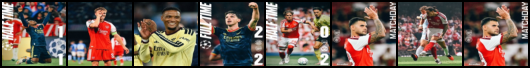

In [59]:
# ミニバッチを 1 つ取り出し，形（枚数・チャネル・高さ・幅）を確かめる
imgs, _ = next(iter(train_loader))
c, h, w = imgs[0].shape
print("ミニバッチサイズ:", len(imgs))
print("チャネル数:", c)
print("画像の高さ:", h)
print("画像の幅:", w)
print(imgs.shape)

# 取り出した画像を並べて表示する
img = torchvision.utils.make_grid(imgs)
img = transforms.functional.to_pil_image(img)
display(img)

In [60]:
check("⑥", globals())

⑥ OK


### コードテンプレート⑦：ネットワークの定義（MLP）

In [61]:
# 入力の数 = チャネル × 高さ × 幅（画像を 1 列に並べたときの長さ）
INPUT_SIZE = c * h * w
# 中間層（隠れ層）のニューロンの数
HIDDEN_SIZE1 = 512
HIDDEN_SIZE2 = 256
# 出力の数 = 分類するクラスの数
OUTPUT_SIZE = len(full_dataset.classes)

# 層を上から順に積み重ねてモデルを作る
model = nn.Sequential(
    # 画像（または特徴マップ）を 1 列のベクトルに伸ばす
    nn.Flatten(),
    # 全結合層：すべての入力とつながる
    nn.Linear(INPUT_SIZE, HIDDEN_SIZE1),
    # 活性化関数：負の値を 0 にする
    nn.ReLU(),
    nn.Linear(HIDDEN_SIZE1, HIDDEN_SIZE2),
    nn.ReLU(),
    nn.Linear(HIDDEN_SIZE2, OUTPUT_SIZE)
)
# モデルを計算装置に載せる
model.to(device)

model

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Linear(in_features=256, out_features=2, bias=True)
)

In [62]:
check("⑦", globals())

MLP｜出力の形 (1, 2)｜パラメータ数 6,423,810
⑦ OK


### コードテンプレート⑧⑨：損失関数と最適化手法

In [63]:
# 損失関数：予測と正解のずれを測る（分類で標準の交差エントロピー）
criterion = nn.CrossEntropyLoss()
# 最適化手法：損失が小さくなる向きに重みを少しずつ動かす（学習率 0.001）
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [64]:
check("⑧⑨", globals())

⑧⑨ OK


## 学習・評価フェーズ（⑩〜⑫）

### コードテンプレート⑩：学習

In [65]:
EPOCHS = 20          # 授業では試行①②③とも 20 エポックにそろえる
# エポックごとの損失と正解率を記録するリスト
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

# 学習時間を測る（授業で追加）
import time
_t0 = time.perf_counter()
# EPOCHS 回，訓練データ全体を繰り返し学習する
for epoch in range(EPOCHS):
    # 訓練モードにする
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Train]', leave=False):
        images, labels = images.to(device), labels.to(device)

        # 前回の勾配を消す → 予測 → 損失を計算 → 誤差逆伝播で勾配を求める → 重みを更新
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        # 最も確率の高いクラスを予測とし，正解の数を数える
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    train_loss /= train_total
    train_accuracy = 100.0 * train_correct / train_total
    train_loss_list.append(train_loss)
    train_acc_list.append(train_accuracy)
    
    # 評価モードにする：ここからは検証データで確かめる（重みは更新しない）
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    # 勾配を計算しない（評価だけなので速く，メモリも少なくて済む）
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Val]', leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    val_loss /= val_total
    val_accuracy = 100.0 * val_correct / val_total
    val_loss_list.append(val_loss)
    val_acc_list.append(val_accuracy)

    # エポックごとの損失と正解率を表示する
    print(f'Epoch {epoch+1}/{EPOCHS},'
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%,'
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%  ')

train_sec = time.perf_counter() - _t0
print(f'学習時間: {train_sec:.1f} 秒')

Epoch 1/20,Train Loss: 1.4804, Train Acc: 46.77%,Val Loss: 0.9847, Val Acc: 61.54%  


Epoch 2/20,Train Loss: 0.9768, Train Acc: 58.06%,Val Loss: 0.9656, Val Acc: 38.46%  


Epoch 3/20,Train Loss: 0.6438, Train Acc: 61.29%,Val Loss: 0.5038, Val Acc: 92.31%  


Epoch 4/20,Train Loss: 0.5198, Train Acc: 70.97%,Val Loss: 1.0276, Val Acc: 46.15%  


Epoch 5/20,Train Loss: 0.4803, Train Acc: 75.81%,Val Loss: 0.7301, Val Acc: 69.23%  


...

Epoch 16/20,Train Loss: 0.0055, Train Acc: 100.00%,Val Loss: 0.1038, Val Acc: 92.31%  


Epoch 17/20,Train Loss: 0.0049, Train Acc: 100.00%,Val Loss: 0.1894, Val Acc: 92.31%  


Epoch 18/20,Train Loss: 0.0032, Train Acc: 100.00%,Val Loss: 0.0402, Val Acc: 100.00%  


Epoch 19/20,Train Loss: 0.0026, Train Acc: 100.00%,Val Loss: 0.0473, Val Acc: 100.00%  


Epoch 20/20,Train Loss: 0.0020, Train Acc: 100.00%,Val Loss: 0.1645, Val Acc: 92.31%  
学習時間: 3.7 秒


In [66]:
check("⑩", globals())

⑩ OK


### コードテンプレート⑪：学習結果の可視化

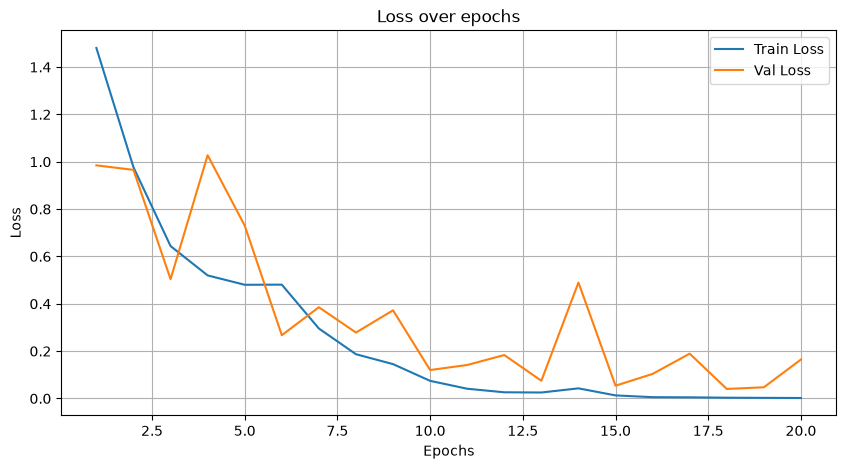

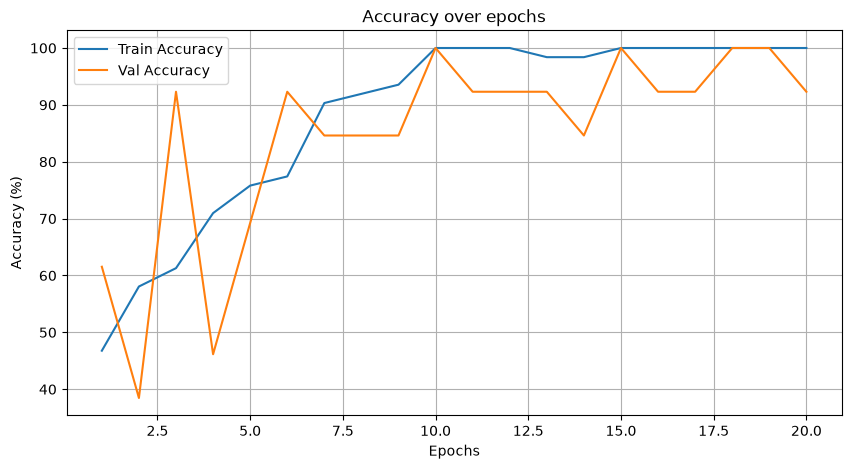

In [67]:
import seaborn as sns
# グラフを描く道具
import matplotlib.pyplot as plt
# 損失と正解率の推移をグラフにする（訓練と検証を比べる）
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 5))

sns.lineplot(x=epochs, y=train_loss_list, label='Train Loss')
sns.lineplot(x=epochs, y=val_loss_list, label='Val Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.lineplot(x=epochs, y=train_acc_list, label='Train Accuracy')
sns.lineplot(x=epochs, y=val_acc_list, label='Val Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()

### コードテンプレート⑫：テストデータでの評価

In [68]:
model.eval()   # 評価モード（学習のときだけ働く Dropout などを止める）
# テストデータ（学習にも検証にも使っていないデータ）で正解率を求める
correct = 0
total = 0
# 勾配を計算しない（評価だけなので速く，メモリも少なくて済む）
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        # 最も確率の高いクラスを予測とし，正解の数を数える
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f'Accuracy: {correct / total * 100:.2f}% ')

Accuracy: 100.00% 


In [69]:
check("⑫", globals())

⑫ OK


## 記録（MLP）

In [70]:
# 記録（MLP のあとと CNN のあとに 1 回ずつ実行する）
from common.logger import ResultLogger
arch = "CNN" if any(isinstance(m, nn.Conv2d) for m in model.modules()) else "MLP"
metrics = {"test_accuracy": correct / total, "val_acc_best": max(val_acc_list) / 100,
           "val_acc_last": val_acc_list[-1] / 100, "train_sec": train_sec,
           "n_class": len(full_dataset.classes), "n_images": len(full_dataset), "n_test": total}
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d4", exercise="ex1", device=device)
logger.log_many(metrics, condition=f"{Path(IMAGE_DIR).name}_{arch}", seed=0)
print(f"{arch}：テスト正解率 {correct / total * 100:.1f}%（{total} 枚中 {correct} 枚）→ {logger.path.name}")

MLP：テスト正解率 100.0%（15 枚中 15 枚）→ c1_d4_ex1.csv


## CNN に替える

⑦を CNN（カード R の形）で書き，**⑧〜⑫は上の自分のセルをコピーして** 下に貼る．⑦を替えたら⑧⑨も実行し直す（optimizer は新しい model の重みを動かす）．

### コードテンプレート⑦：ネットワークの定義（CNN）

In [83]:
# 入力画像のチャネル数・高さ・幅
INPUT_CHANNELS = c
IMAGE_HEIGHT = h
IMAGE_WIDTH = w

# 畳み込み層が出す特徴マップの枚数
CONV1_OUT_CHANNELS = 16

# 3×3 のフィルタで画像をなぞる．PADDING で縁を補い，POOL_SIZE で縦横を半分にする
KERNEL_SIZE = 3
PADDING = 1
POOL_SIZE = 2

POOL_NUM = 1

FC1_OUT_CHANNELS = 128

# 出力の数 = 分類するクラスの数
OUTPUT_SIZE = len(full_dataset.classes)

# プーリング後の高さと幅（64 → 32）
OUT_HEIGHT = IMAGE_HEIGHT // (POOL_SIZE ** POOL_NUM)
OUT_WIDTH = IMAGE_WIDTH // (POOL_SIZE ** POOL_NUM)

# 全結合層に渡す長さ = 特徴マップの枚数 × 高さ × 幅
FLATTEN_SIZE = CONV1_OUT_CHANNELS * OUT_HEIGHT * OUT_WIDTH 

# 層を上から順に積み重ねてモデルを作る
model = nn.Sequential(
    # 畳み込み層：小さなフィルタで模様（特徴）を取り出す
    nn.Conv2d(INPUT_CHANNELS, CONV1_OUT_CHANNELS, kernel_size=KERNEL_SIZE, padding=PADDING),
    # 活性化関数：負の値を 0 にする
    nn.ReLU(),
    # プーリング：2×2 の中の最大値だけを残して縮小する
    nn.MaxPool2d(kernel_size=POOL_SIZE),
    # 画像（または特徴マップ）を 1 列のベクトルに伸ばす
    nn.Flatten(),
    # 全結合層：すべての入力とつながる
    nn.Linear(FLATTEN_SIZE, FC1_OUT_CHANNELS),
    nn.ReLU(),
    nn.Linear(FC1_OUT_CHANNELS, OUTPUT_SIZE)
)

# モデルを計算装置に載せる
model = model.to(device)

# 試しに 1 枚分のデータを通し，出力の形が (1, 2) になるかを確かめる
dummy_input = torch.randn(1, INPUT_CHANNELS, IMAGE_HEIGHT, IMAGE_WIDTH).to(device)
output = model(dummy_input)
print("ダミー入力の出力サイズ:", output.shape)
print("　↑　")
print("torch.Size([1,2]) になることを確認してください。")

model

ダミー入力の出力サイズ: torch.Size([1, 2])
　↑　
torch.Size([1,2]) になることを確認してください。


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=16384, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=2, bias=True)
)

In [84]:
check("⑦", globals())

CNN｜出力の形 (1, 2)｜パラメータ数 2,097,986
⑦ OK


### コードテンプレート⑧⑨：損失関数と最適化手法

上の⑧⑨をコピーして貼る．

In [85]:
# 損失関数：予測と正解のずれを測る（分類で標準の交差エントロピー）
criterion = nn.CrossEntropyLoss()
# 最適化手法：損失が小さくなる向きに重みを少しずつ動かす（学習率 0.001）
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [86]:
check("⑧⑨", globals())

⑧⑨ OK


### コードテンプレート⑩：学習

上の⑩をコピーして貼る．

In [87]:
EPOCHS = 20          # 授業では試行①②③とも 20 エポックにそろえる
# エポックごとの損失と正解率を記録するリスト
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

# 学習時間を測る（授業で追加）
import time
_t0 = time.perf_counter()
# EPOCHS 回，訓練データ全体を繰り返し学習する
for epoch in range(EPOCHS):
    # 訓練モードにする
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Train]', leave=False):
        images, labels = images.to(device), labels.to(device)

        # 前回の勾配を消す → 予測 → 損失を計算 → 誤差逆伝播で勾配を求める → 重みを更新
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        # 最も確率の高いクラスを予測とし，正解の数を数える
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    train_loss /= train_total
    train_accuracy = 100.0 * train_correct / train_total
    train_loss_list.append(train_loss)
    train_acc_list.append(train_accuracy)
    
    # 評価モードにする：ここからは検証データで確かめる（重みは更新しない）
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    # 勾配を計算しない（評価だけなので速く，メモリも少なくて済む）
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Val]', leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    val_loss /= val_total
    val_accuracy = 100.0 * val_correct / val_total
    val_loss_list.append(val_loss)
    val_acc_list.append(val_accuracy)

    # エポックごとの損失と正解率を表示する
    print(f'Epoch {epoch+1}/{EPOCHS},'
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%,'
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%  ')

train_sec = time.perf_counter() - _t0
print(f'学習時間: {train_sec:.1f} 秒')

Epoch 1/20,Train Loss: 1.1507, Train Acc: 48.39%,Val Loss: 0.6538, Val Acc: 61.54%  


Epoch 2/20,Train Loss: 0.6725, Train Acc: 56.45%,Val Loss: 0.6982, Val Acc: 38.46%  


Epoch 3/20,Train Loss: 0.6925, Train Acc: 51.61%,Val Loss: 0.6816, Val Acc: 46.15%  


Epoch 4/20,Train Loss: 0.5905, Train Acc: 75.81%,Val Loss: 0.5294, Val Acc: 69.23%  


Epoch 5/20,Train Loss: 0.5243, Train Acc: 82.26%,Val Loss: 0.4383, Val Acc: 100.00%  


...

Epoch 16/20,Train Loss: 0.0136, Train Acc: 100.00%,Val Loss: 0.0566, Val Acc: 100.00%  


Epoch 17/20,Train Loss: 0.0110, Train Acc: 100.00%,Val Loss: 0.0404, Val Acc: 100.00%  


Epoch 18/20,Train Loss: 0.0092, Train Acc: 100.00%,Val Loss: 0.0366, Val Acc: 100.00%  


Epoch 19/20,Train Loss: 0.0079, Train Acc: 100.00%,Val Loss: 0.0412, Val Acc: 100.00%  


Epoch 20/20,Train Loss: 0.0070, Train Acc: 100.00%,Val Loss: 0.0384, Val Acc: 100.00%  
学習時間: 2.3 秒


In [88]:
check("⑩", globals())

⑩ OK


### コードテンプレート⑪：学習結果の可視化

上の⑪をコピーして貼る．

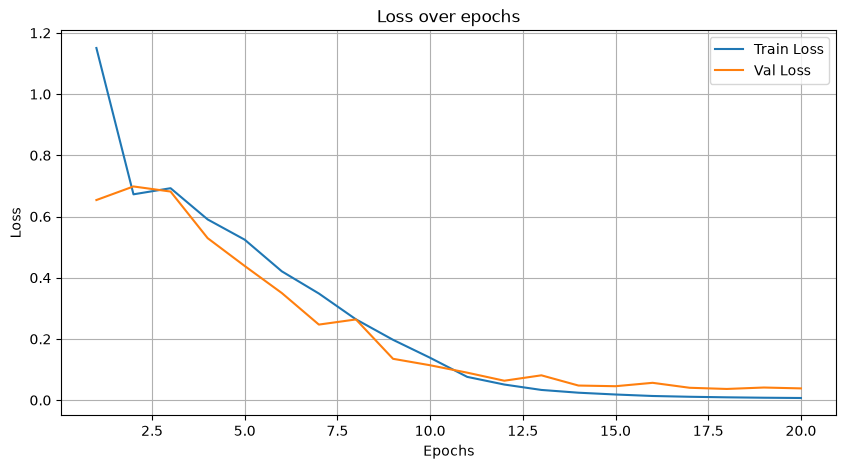

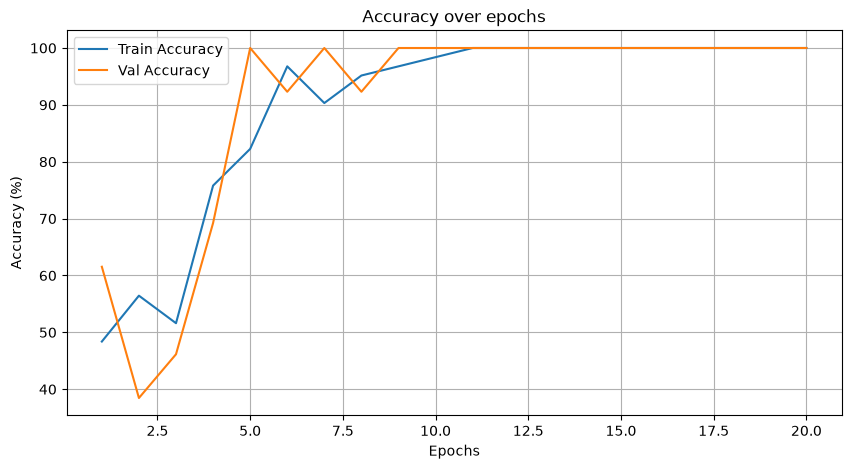

In [89]:
import seaborn as sns
# グラフを描く道具
import matplotlib.pyplot as plt
# 損失と正解率の推移をグラフにする（訓練と検証を比べる）
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 5))

sns.lineplot(x=epochs, y=train_loss_list, label='Train Loss')
sns.lineplot(x=epochs, y=val_loss_list, label='Val Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.lineplot(x=epochs, y=train_acc_list, label='Train Accuracy')
sns.lineplot(x=epochs, y=val_acc_list, label='Val Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()

### コードテンプレート⑫：テストデータでの評価

上の⑫をコピーして貼る．

In [90]:
model.eval()   # 評価モード（学習のときだけ働く Dropout などを止める）
# テストデータ（学習にも検証にも使っていないデータ）で正解率を求める
correct = 0
total = 0
# 勾配を計算しない（評価だけなので速く，メモリも少なくて済む）
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        # 最も確率の高いクラスを予測とし，正解の数を数える
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f'Accuracy: {correct / total * 100:.2f}% ')

Accuracy: 100.00% 


In [91]:
check("⑫", globals())

⑫ OK


## 記録（CNN）

In [92]:
# 記録（MLP のあとと CNN のあとに 1 回ずつ実行する）
from common.logger import ResultLogger
arch = "CNN" if any(isinstance(m, nn.Conv2d) for m in model.modules()) else "MLP"
metrics = {"test_accuracy": correct / total, "val_acc_best": max(val_acc_list) / 100,
           "val_acc_last": val_acc_list[-1] / 100, "train_sec": train_sec,
           "n_class": len(full_dataset.classes), "n_images": len(full_dataset), "n_test": total}
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d4", exercise="ex1", device=device)
logger.log_many(metrics, condition=f"{Path(IMAGE_DIR).name}_{arch}", seed=0)
print(f"{arch}：テスト正解率 {correct / total * 100:.1f}%（{total} 枚中 {correct} 枚）→ {logger.path.name}")

CNN：テスト正解率 100.0%（15 枚中 15 枚）→ c1_d4_ex1.csv


## モデルを保存する（演習3で使う）

ファイルに入るのは **重みの数値（`state_dict`）** だけ．構造（層の形）は入らないので，演習3では⑦をもう一度書いて組み立て直す．
クラス名と画像の大きさは，推論のときに要るので一緒に保存する．

In [93]:
if arch != "CNN":
    raise RuntimeError("いまの model は MLP．CNN の⑦〜⑫を実行してから保存する")
SAVE_PATH = ROOT / "results" / "my_cnn.pt"
torch.save({
    "state_dict": model.state_dict(),          # 学習した重み（数値だけ）
    "classes": full_dataset.classes,           # クラス名（フォルダ名）．出力の 0, 1, … がどのクラスか
    "image_size": h,                           # ②でそろえた大きさ（64）
    "test_accuracy": correct / total,
}, SAVE_PATH)
print("保存した:", SAVE_PATH, f"({SAVE_PATH.stat().st_size / 1e6:.1f} MB)")

保存した: /Users/itagakisogo/AI_TD/results/my_cnn.pt (8.4 MB)


## 振り返り（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 自分のデータの 2 つのクラスと，それを選んだ理由：アーセナルFCのホームユニフォームかアウェイユニフォームを着た選手の判別。好きなサッカーチームにまつわるものにしようと思ったから
2. 書いていて止まった所と，どう直したか：＿＿
3. MLP と CNN のテスト正解率（1 回ずつ）．この 1 回の差で「CNN の方が良い」と言えると思うか：＿＿